# iPhone или Android: метод k ближайших соседей
**Практическое задание № 1 · самостоятельное решение**

Цель: по ответам анкеты предсказать класс телефона методом k-NN.

В работе: проверка данных, кодирование ответов, подбор k, независимая проверка, графики, разбор соседей и форма для новой анкеты.

In [23]:
import io, base64, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11})
SEED = 42

In [24]:
from google.colab import drive
import pandas as pd
import numpy as np

# Подключаем Google Диск — Colab попросит разрешить доступ.
drive.mount('/content/drive')

# Укажи путь к своему CSV.
# Здесь файл лежит прямо в разделе «Мой диск».
CSV_PATH = (
    '/content/drive/MyDrive/'
    'Предпочтение пользователей Iphone или android.csv'
)

raw = pd.read_csv(CSV_PATH, encoding='utf-8-sig')

assert raw.shape[1] == 23, (
    f'Ожидалось 23 столбца, найдено {raw.shape[1]}. Проверь файл.'
)

# Короткие названия для остальных ячеек блокнота.
raw.columns = [
    'timestamp', 'stability', 'photo_freq', 'blog', 'pay_extra',
    'status_tech', 'vpn', 'age', 'budget', 'custom_ui',
    'ringtone', 'resale', 'system_tune', 'change_freq', 'os_support',
    'sphere', 'gender', 'instagram', 'charge_times', 'save_or_spend',
    'headset', 'apples', 'target'
]

# Нумеруем анкеты с единицы.
raw.index = np.arange(1, len(raw) + 1)

print('Загружено анкет:', len(raw))
display(raw.head(3))
display(raw['target'].value_counts().rename('Количество').to_frame())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Загружено анкет: 41


,timestamp,stability,photo_freq,blog,pay_extra,status_tech,vpn,age,budget,custom_ui,...,change_freq,os_support,sphere,gender,instagram,charge_times,save_or_spend,headset,apples,target
1,2026/09/14 8:05:47 PM GMT+3,Стабильность,Раз в неделю,Нет,Экосистема;Надежность,Технологичность,VPN,21,80000.0,5,...,3.0,Не важна,IT,М,Нет,1.0,Экономить и откладывать,От одного бренда,1,Андроид
2,2026/09/14 8:05:56 PM GMT+3,Стабильность,Каждый день,Да,Статус;Камера,Статус,VPN,21,90000.0,6,...,3.0,Важна,Продажи,М,Да,5.0,Экономить и откладывать,От одного бренда,7,Айфон
3,2026/09/14 8:06:41 PM GMT+3,Новшество,Раз в неделю,Нет,Экосистема;Надежность;Мультивыбор,Статус,VPN,22,60.0,5,...,3.0,Важна,Менеджер,М,Нет,2.0,Порадовать себя,От одного бренда,4,Айфон


,Количество
target,
Андроид,22
Айфон,19


## 1. Подготовка данных
Каждый человек — строка таблицы; ответы — признаки; телефон — правильный ответ.

Принятые **условности**, которые нужно озвучить:
- Бюджеты от 0 до 1000 считаем тысячами рублей: 60 → 60 000.
- Для этой студенческой анкеты возраст вне 15–100 лет считаем сомнительным и исключаем всю запись.
- Объединяем явные варианты IT/ИТ/программист/разработка. Остальные сферы не пытаемся угадать.
- Вопрос с несколькими ответами превращаем в отдельные признаки 0/1.
- Время заполнения и ответ про телефон не входят в признаки.
- Вопрос про яблоки оставляем как в анкете.

Категории кодируем отдельными индикаторами: «дизайн» не становится числом, которое искусственно “ближе” к IT, чем продажи.

Числовые признаки приводим к сопоставимому масштабу.

Исключённые сомнительные записи:


,age,budget,sphere,target
41,5,3.0,5,Андроид


Осталось анкет: 40 | исходных признаков модели: 24
target
Android    21
iPhone     19


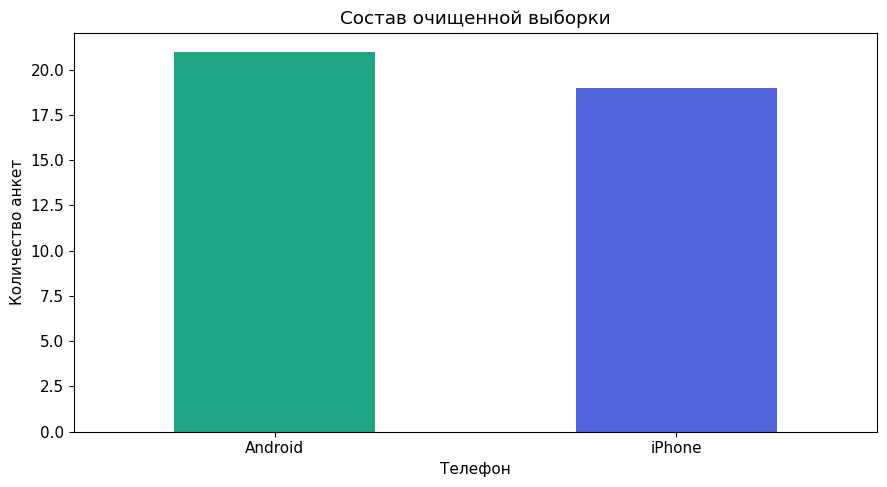

In [25]:
numeric_cols = ['age', 'budget', 'custom_ui', 'change_freq', 'charge_times', 'apples']
cat_cols = ['stability', 'photo_freq', 'blog', 'status_tech', 'vpn', 'ringtone',
            'resale', 'system_tune', 'os_support', 'sphere', 'gender', 'instagram',
            'save_or_spend', 'headset']
pay_options = ['Статус', 'Камера', 'Экосистема', 'Надежность']
pay_cols = ['pay_' + x for x in pay_options]

def prepare_features(frame):
    """Только фиксированные правила; здесь нет обучения на всей выборке."""
    result = frame.copy()
    for c in cat_cols:
        result[c] = result[c].map(lambda x: str(x).strip().lower() if pd.notna(x) else np.nan)
    it_names = {'it', 'ит', 'программирование', 'программист', 'разработка',
                'тех под', 'корпоративные системы'}
    result['sphere'] = result['sphere'].replace({s: 'it' for s in it_names})
    for c in numeric_cols:
        result[c] = pd.to_numeric(result[c].astype(str).str.replace(' ', '', regex=False)
                                  .str.replace(',', '.', regex=False), errors='coerce')
    result.loc[result['budget'].between(0, 1000, inclusive='neither'), 'budget'] *= 1000
    result.loc[result['budget'] <= 0, 'budget'] = np.nan
    for c in ['custom_ui', 'apples']:
        result.loc[~result[c].between(1, 10), c] = np.nan
    for c in ['change_freq', 'charge_times']:
        result.loc[result[c] <= 0, c] = np.nan
    selections = frame['pay_extra'].fillna('').map(
        lambda x: {s.strip().casefold().replace('ё', 'е') for s in str(x).split(';')})
    for option, col in zip(pay_options, pay_cols):
        result[col] = selections.map(lambda s: int(option.casefold() in s))
    return result[numeric_cols + cat_cols + pay_cols]

features = prepare_features(raw)
valid = features['age'].between(15, 100) & raw['target'].isin(['Айфон', 'Андроид'])
print('Исключённые сомнительные записи:')
display(raw.loc[~valid, ['age', 'budget', 'sphere', 'target']])
X = features.loc[valid].copy()
y = raw.loc[valid, 'target'].replace({'Айфон': 'iPhone', 'Андроид': 'Android'})
assert 'target' not in X and 'timestamp' not in X
print('Осталось анкет:', len(X), '| исходных признаков модели:', X.shape[1])
print(y.value_counts().to_string())
fig, ax = plt.subplots()
y.value_counts().reindex(['Android', 'iPhone']).plot.bar(ax=ax, color=['#20a486', '#5164d9'], rot=0)
ax.set(title='Состав очищенной выборки', ylabel='Количество анкет', xlabel='Телефон')
plt.tight_layout(); plt.show()

## 2. Честная проверка и подбор k
Откладываем 25% анкет для итоговой проверки. Модель не видит их ответы при обучении или выборе k.

На оставшихся 75% сравниваем k = 1, 3, 5, 7, 9 с помощью пяти проверок: каждый раз четыре части обучают модель, пятая её проверяет. Выбираем k с лучшей средней точностью. Одновременно выполняется масштабирование и кодирование **только по обучающей части** каждой проверки — это обеспечивает Pipeline.

Все варианты используют одинаковое голосование, евклидово расстояние и одинаковую подготовку. Меняется только k. Слишком маленькое k чувствительно к случайным ответам; слишком большое сглаживает различия. Нечётное k помогает избежать ничьей при двух классах.

По средней точности кросс-валидации k = 1 и k = 9 показали одинаковый результат. Из этих вариантов я выбрал девять соседей, чтобы прогноз опирался на большинство среди группы похожих людей и меньше зависел от одной анкеты. Это осознанный выбор между вариантами с одинаковой средней точностью, а не доказательство превосходства k = 9.

Обучение: 30, независимый тест: 10. Выбрано k = 9


,k,Средняя точность CV,Разброс (std)
0,1,0.667,0.183
1,3,0.633,0.194
2,5,0.633,0.125
3,7,0.633,0.194
4,9,0.667,0.236


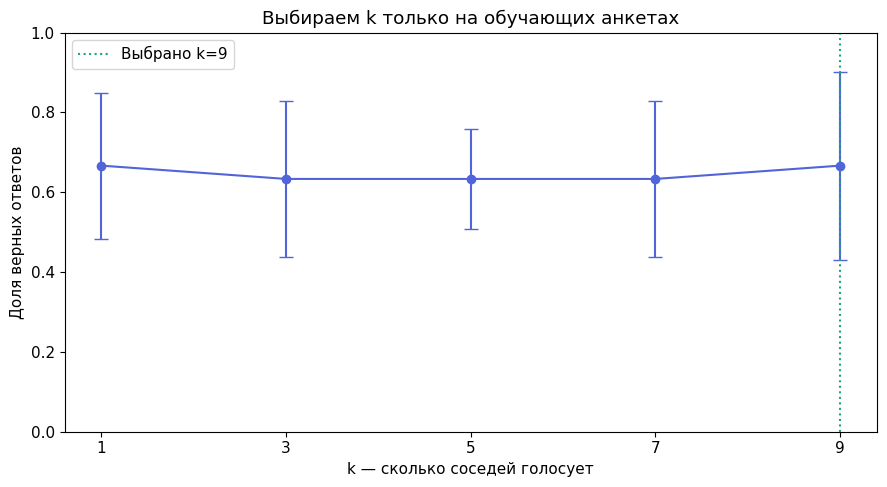

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y)
preprocessor = ColumnTransformer([
    ('numbers', Pipeline([('fill', SimpleImputer(strategy='median')),
                          ('scale', StandardScaler())]), numeric_cols),
    ('categories', Pipeline([('fill', SimpleImputer(strategy='most_frequent')),
                             ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols),
    ('multi', 'passthrough', pay_cols)
])
pipe = Pipeline([('prepare', preprocessor),
                 ('knn', KNeighborsClassifier(weights='uniform', metric='euclidean', algorithm='brute'))])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
search = GridSearchCV(pipe, {'knn__n_neighbors': [1, 3, 5, 7, 9]},
                      scoring='accuracy', cv=cv, refit=True, error_score='raise')
search.fit(X_train, y_train)
model = search.best_estimator_
best_k = search.best_params_['knn__n_neighbors']
cv_table = pd.DataFrame({'k': search.cv_results_['param_knn__n_neighbors'].astype(int),
                         'Средняя точность CV': search.cv_results_['mean_test_score'],
                         'Разброс (std)': search.cv_results_['std_test_score']})
print(f'Обучение: {len(X_train)}, независимый тест: {len(X_test)}. Выбрано k = {best_k}')
display(cv_table.round(3))
fig, ax = plt.subplots()
ax.errorbar(cv_table['k'], cv_table['Средняя точность CV'],
            yerr=cv_table['Разброс (std)'], fmt='o-', capsize=5, color='#5164d9')
ax.set(xticks=cv_table['k'], xlabel='k — сколько соседей голосует', ylabel='Доля верных ответов',
       title='Выбираем k только на обучающих анкетах', ylim=(0, 1))
ax.axvline(best_k, linestyle=':', color='#20a486', label=f'Выбрано k={best_k}')
ax.legend(); plt.tight_layout(); plt.show()

## 3. Итоговый тест
Accuracy — доля верных ответов. Например, 7 верных из 10 = 70%. Матрица ошибок показывает, какие классы перепутаны. В строках — настоящий телефон, в столбцах — прогноз.

Сравниваем с простым ориентиром: всегда отвечать самым частым классом( телефоном) **обучающей** выборки. Если k-NN не обгоняет его, нельзя заявлять, что модель полезна. Маленький тест даёт нестабильную оценку: одна ошибка меняет процент на 10 пунктов.

k-NN: 8/10 правильных ответов = 80%
Всегда наиболее частый класс: 50%
Средняя полнота двух классов (balanced accuracy): 80%
              precision    recall  f1-score   support

     Android       0.71      1.00      0.83         5
      iPhone       1.00      0.60      0.75         5

    accuracy                           0.80        10
   macro avg       0.86      0.80      0.79        10
weighted avg       0.86      0.80      0.79        10



,Настоящий телефон,Прогноз,Верно
Анкета №,,,
16,Android,Android,True
26,Android,Android,True
28,iPhone,Android,False
18,Android,Android,True
17,iPhone,iPhone,True
35,Android,Android,True
8,iPhone,iPhone,True
2,iPhone,iPhone,True
3,iPhone,Android,False


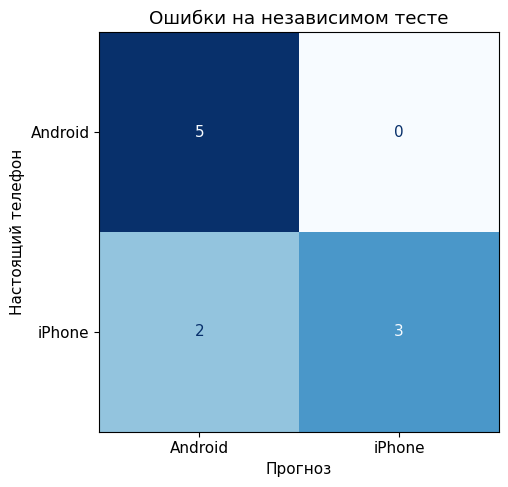

Вывод: На этом тесте k-NN лучше простого ориентира.


In [27]:
pred = model.predict(X_test)
accuracy = accuracy_score(y_test, pred)
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
baseline_accuracy = accuracy_score(y_test, baseline.predict(X_test))
correct = int((pred == y_test.to_numpy()).sum())
print(f'k-NN: {correct}/{len(y_test)} правильных ответов = {accuracy:.0%}')
print(f'Всегда наиболее частый класс: {baseline_accuracy:.0%}')
print(f'Средняя полнота двух классов (balanced accuracy): {balanced_accuracy_score(y_test, pred):.0%}')
print(classification_report(y_test, pred, labels=['Android', 'iPhone'], zero_division=0))
test_results = pd.DataFrame({'Настоящий телефон': y_test, 'Прогноз': pred})
test_results['Верно'] = test_results['Настоящий телефон'] == test_results['Прогноз']
display(test_results.rename_axis('Анкета №'))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=['Android', 'iPhone'],
                                       cmap='Blues', colorbar=False, ax=ax)
ax.set(title='Ошибки на независимом тесте', xlabel='Прогноз', ylabel='Настоящий телефон')
plt.tight_layout(); plt.show()
print('Вывод:', 'На этом тесте k-NN лучше простого ориентира.' if accuracy > baseline_accuracy
      else 'На этом тесте k-NN не лучше простого ориентира.')

## 4. Человек как точка: показываем реальных соседей
После кодирования у человека много координат. Расстояние между двумя анкетами:

$$d(x,z)=\sqrt{\sum_j (x_j-z_j)^2}.$$

PCA сжимает координаты до двух для картинки. Цвет — телефон, звезда — проверяемая анкета, обводки и линии — её **настоящие ближайшие соседи в полном пространстве признаков**. Они могут выглядеть не самыми близкими на плоской карте: проекция теряет часть информации. По двум координатам PCA модель не обучается.

График и таблица — объяснение прогноза, а не причинная связь между привычками и телефоном.

Тестовая анкета № 16 | Прогноз: Android | k = 9
Настоящий телефон: Android


,Анкета №,Телефон соседа,Расстояние
0,20,Android,3.227
1,33,Android,3.425
2,37,Android,3.487
3,23,Android,3.612
4,9,Android,3.907
5,29,Android,3.936
6,25,Android,3.950
7,36,iPhone,3.992
8,27,Android,4.123


Голоса: Android: 8, iPhone: 1


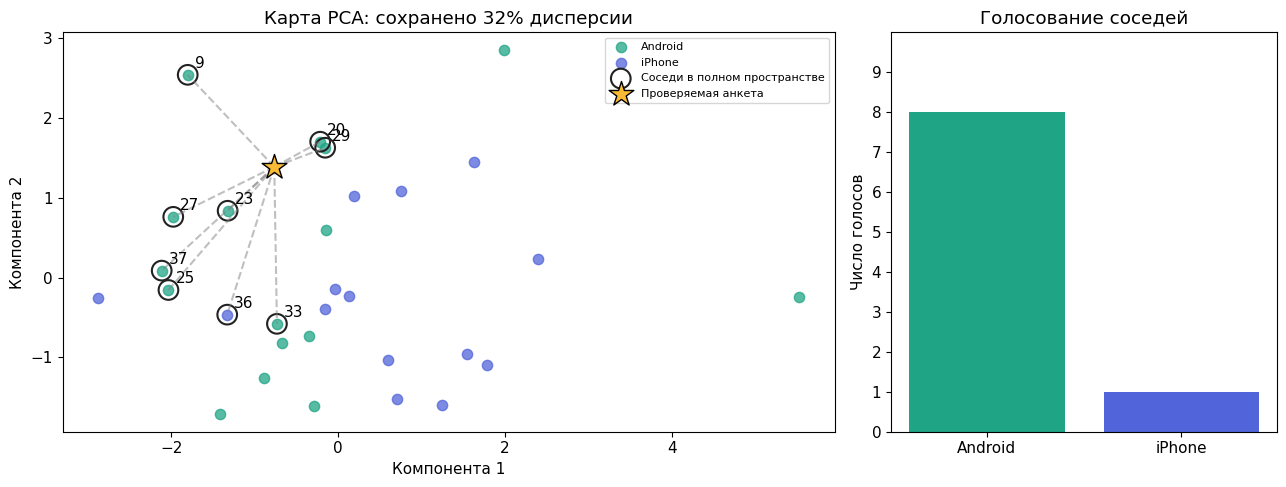

In [28]:
train_vectors = model.named_steps['prepare'].transform(X_train)
pca = PCA(n_components=2).fit(train_vectors)  # Только обучение.
train_xy = pca.transform(train_vectors)
colors = {'Android': '#20a486', 'iPhone': '#5164d9'}

def explain_prediction(person, title='Новая анкета', truth=None):
    """person — DataFrame с одной строкой подготовленных признаков."""
    vector = model.named_steps['prepare'].transform(person)
    distances, positions = model.named_steps['knn'].kneighbors(vector)
    positions, distances = positions[0], distances[0]
    answer = model.predict(person)[0]
    neighbors = pd.DataFrame({'Анкета №': X_train.index[positions],
                              'Телефон соседа': y_train.iloc[positions].to_numpy(),
                              'Расстояние': distances})
    print(title, '| Прогноз:', answer, '| k =', best_k)
    if truth is not None: print('Настоящий телефон:', truth)
    display(neighbors.round({'Расстояние': 3}))
    votes = neighbors['Телефон соседа'].value_counts().reindex(['Android', 'iPhone'], fill_value=0)
    print('Голоса:', ', '.join(f'{name}: {count}' for name, count in votes.items()))
    xy = pca.transform(vector)[0]
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [2, 1]})
    ax = axes[0]
    for label, color in colors.items():
        mask = y_train.to_numpy() == label
        ax.scatter(train_xy[mask, 0], train_xy[mask, 1], c=color, s=55, alpha=.75, label=label)
    ax.scatter(train_xy[positions, 0], train_xy[positions, 1], s=200,
               facecolors='none', edgecolors='#222', linewidths=1.5, label='Соседи в полном пространстве')
    for pos in positions:
        ax.plot([xy[0], train_xy[pos, 0]], [xy[1], train_xy[pos, 1]], '--', color='gray', alpha=.5)
        ax.annotate(str(X_train.index[pos]), train_xy[pos], xytext=(5, 5), textcoords='offset points')
    ax.scatter(*xy, marker='*', s=350, c='#f9bb35', edgecolors='black', label='Проверяемая анкета', zorder=5)
    retained = pca.explained_variance_ratio_.sum()
    ax.set(title=f'Карта PCA: сохранено {retained:.0%} дисперсии', xlabel='Компонента 1', ylabel='Компонента 2')
    ax.legend(fontsize=8)
    axes[1].bar(votes.index, votes.to_numpy(), color=[colors[s] for s in votes.index])
    axes[1].set(title='Голосование соседей', ylabel='Число голосов', ylim=(0, best_k + 1))
    axes[1].set_yticks(range(best_k + 1))
    plt.tight_layout(); plt.show()
    return answer

# Одна заранее выбранная тестовая анкета, без подбора удачного примера.
demo_id = X_test.index[0]
_ = explain_prediction(X_test.loc[[demo_id]], f'Тестовая анкета № {demo_id}', y_test.loc[demo_id])

## 5. Проверка новой анкеты
Ниже пример новых ответов (это вымышленный человек). Измените значения в словаре и выполните ячейку. Возраст — в годах, бюджет — в рублях, шкалы — от 1 до 10. Целевой телефон вводить не нужно.

После запуска всего блокнота появится и форма с полями. Измените ответы и нажмите «Прогнозировать»: карта и соседи обновятся. Если среда не поддерживает виджеты, словарь остаётся рабочим способом ввода.

Для демонстрации сохраняем модель из проверки на 30 анкетах: это позволяет показывать, какие именно обучающие люди голосуют. Отдельного дообучения на тесте нет.

Вымышленная новая анкета | Прогноз: Android | k = 9


,Анкета №,Телефон соседа,Расстояние
0,20,Android,2.352
1,33,Android,2.820
2,37,Android,3.026
3,23,Android,3.276
4,36,iPhone,3.405
5,1,Android,3.607
6,25,Android,3.665
7,29,Android,3.909
8,27,Android,4.047


Голоса: Android: 8, iPhone: 1


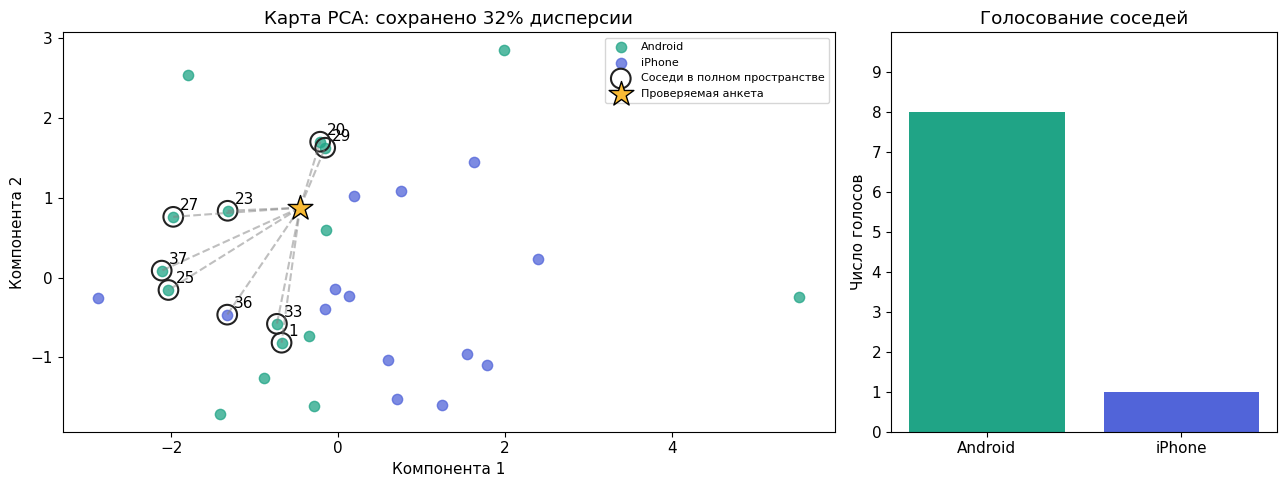

In [36]:
new_person = {
    'stability': 'Стабильность', 'photo_freq': 'Каждый день', 'blog': 'Нет',
    'pay_extra': 'Камера;Надежность', 'status_tech': 'Технологичность', 'vpn': 'VPN',
    'age': 22, 'budget': 60000, 'custom_ui': 7, 'ringtone': 'Да', 'resale': 'Хорошо',
    'system_tune': 'Да', 'change_freq': 3, 'os_support': 'Важна', 'sphere': 'IT',
    'gender': 'М', 'instagram': 'Нет', 'charge_times': 1,
    'save_or_spend': 'Экономить и откладывать', 'headset': 'От разных брендов', 'apples': 5
}
_ = explain_prediction(prepare_features(pd.DataFrame([new_person])), 'Вымышленная новая анкета')

In [30]:
# Необязательная удобная форма.
try:
    import ipywidgets as widgets
except ImportError:
    print('Виджеты недоступны. Измените словарь new_person в предыдущей ячейке.')
else:
    labels = {
        'stability': 'Стабильность/новшество', 'photo_freq': 'Частота фото', 'blog': 'Ведёте блог?',
        'status_tech': 'Статус/технологичность', 'vpn': 'VPN/запрет', 'age': 'Возраст',
        'budget': 'Бюджет, ₽', 'custom_ui': 'Кастомизация (1–10)', 'ringtone': 'Рингтон из файла',
        'resale': 'Перепродажа телефона', 'system_tune': 'Настройка под себя', 'change_freq': 'Смена, лет',
        'os_support': 'Поддержка старой ОС', 'sphere': 'Сфера деятельности', 'gender': 'Пол',
        'instagram': 'Ведёте Instagram?', 'charge_times': 'Зарядок за день',
        'save_or_spend': 'Экономить/порадовать', 'headset': 'Бренды гарнитуры', 'apples': 'Яблоки (1–10)'}
    fields = {}
    for key in numeric_cols + cat_cols:
        kwargs = {'description': labels[key], 'style': {'description_width': '180px'},
                  'layout': widgets.Layout(width='550px')}
        if key in numeric_cols:
            fields[key] = widgets.FloatText(value=new_person[key], **kwargs)
        elif key == 'sphere':
            fields[key] = widgets.Text(value=new_person[key], **kwargs)
        else:
            options = sorted(set(raw.loc[valid, key].dropna().astype(str).str.strip()) | {new_person[key]})
            fields[key] = widgets.Dropdown(options=options, value=new_person[key], **kwargs)
    multi = widgets.SelectMultiple(options=pay_options, value=('Камера', 'Надежность'),
                                   description='Переплата за', style={'description_width': '180px'},
                                   layout=widgets.Layout(width='550px'))
    button = widgets.Button(description='Прогнозировать', button_style='primary')
    output = widgets.Output()
    def on_predict(_):
        with output:
            output.clear_output(wait=True)
            person = {key: field.value for key, field in fields.items()}
            person['pay_extra'] = ';'.join(multi.value)
            if not 15 <= person['age'] <= 100 or person['budget'] <= 0:
                print('Введите возраст 15–100 и положительный бюджет.'); return
            if any(not 1 <= person[key] <= 10 for key in ['custom_ui', 'apples']):
                print('Значения шкал должны быть от 1 до 10.'); return
            if any(person[key] <= 0 for key in ['change_freq', 'charge_times']):
                print('Период смены и число зарядок должны быть положительными.'); return
            explain_prediction(prepare_features(pd.DataFrame([person])), 'Ваша анкета')
    button.on_click(on_predict)
    display(widgets.VBox(list(fields.values()) + [multi, button, output]))